<a href="https://colab.research.google.com/github/varsityboi/speech-emotion-recognition/blob/main/notebooks/01_eda.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 01. Exploratory data analysis and preprocessing

This notebook downloads CREMA-D and RAVDESS, checks the audio files and explores the data: class balance, speakers, clip length, silence, human listener agreement and basic acoustic features. It then turns every clip into a fixed-size log-Mel spectrogram and creates the speaker-independent train / val / test split used by all later notebooks.

**Inputs** (Google Drive `MyDrive/SER_Project`):
- Nothing from Drive. The audio is downloaded from Kaggle with `kagglehub`. The CREMA-D speaker demographics and listener ratings are downloaded from the CREMA-D GitHub repository.

**Outputs** (Google Drive `MyDrive/SER_Project`):
- `metadata.csv`: one row per clip with labels, speaker details, duration, silence and listener votes
- `acoustic_features_sample.csv`: loudness, pitch and brightness for a sample of clips
- `logmel_X.npy`: log-Mel spectrograms with per-clip peak normalisation
- `logmel_index.csv`: clip index with labels and the train / val / test / ravdess_test split
- `norm_stats.npz`: per-mel-band mean and standard deviation of the training set
- `logmel_X_noscale.npy` and `norm_stats_noscale.npz`: the same without per-clip volume scaling (last cell)
- `figures/01_class_distribution.png` to `figures/09_preprocessing_before_after.png`

### Setup
Mounts Google Drive, creates the project folder and imports the libraries. All notebooks read and write their files in this folder.

In [2]:

from google.colab import drive
drive.mount('/content/drive')

import os
PROJECT_DIR = "/content/drive/MyDrive/SER_Project"
os.makedirs(PROJECT_DIR, exist_ok=True)


import glob
import numpy as np
import pandas as pd
import soundfile as sf
import librosa
from tqdm.auto import tqdm
import kagglehub

tqdm.pandas()
print("All set! Project folder:", PROJECT_DIR)
print("librosa version:", librosa.__version__)

Mounted at /content/drive
All set! Project folder: /content/drive/MyDrive/SER_Project
librosa version: 0.11.0


### Download the datasets
Downloads CREMA-D and RAVDESS from Kaggle and lists every .wav file in each.

In [3]:

crema_root = kagglehub.dataset_download("ejlok1/cremad")
ravdess_root = kagglehub.dataset_download("uwrfkaggler/ravdess-emotional-speech-audio")
crema_files = glob.glob(os.path.join(crema_root, "**", "*.wav"), recursive=True)
ravdess_files = glob.glob(os.path.join(ravdess_root, "**", "*.wav"), recursive=True)

print("CREMA-D folder:", crema_root)
print("CREMA-D .wav files:", len(crema_files))
print("RAVDESS folder:", ravdess_root)
print("RAVDESS .wav files:", len(ravdess_files))

100%|██████████| 451M/451M [00:03<00:00, 144MB/s]

Extracting files...


100%|██████████| 429M/429M [00:02<00:00, 157MB/s]

Extracting files...


CREMA-D folder: /root/.cache/kagglehub/datasets/ejlok1/cremad/versions/1
CREMA-D .wav files: 7442
RAVDESS folder: /root/.cache/kagglehub/datasets/uwrfkaggler/ravdess-emotional-speech-audio/versions/1
RAVDESS .wav files: 2880


### Read the CREMA-D file names
Each CREMA-D file name holds the actor, sentence, emotion and intensity. This cell splits the names and builds a table with one row per clip.

In [4]:
CREMA_EMO = {"ANG": "angry", "DIS": "disgust", "FEA": "fear",
             "HAP": "happy", "NEU": "neutral", "SAD": "sad"}
CREMA_INT = {"LO": "low", "MD": "medium", "HI": "high",
             "XX": "unspecified", "X": "unspecified"}

rows, bad = [], []
for path in crema_files:
    name = os.path.basename(path)
    try:
        actor, sentence, emo, inten = name[:-4].split("_")
        rows.append({"path": path, "file": name, "dataset": "CREMA-D",
                     "actor_num": int(actor), "speaker_id": f"crema_{actor}",
                     "sentence": sentence, "emotion": CREMA_EMO[emo],
                     "intensity": CREMA_INT[inten]})
    except (ValueError, KeyError):
        bad.append(name)

crema = pd.DataFrame(rows).drop_duplicates("file").reset_index(drop=True)
print("Clips:", len(crema), "| Speakers:", crema.speaker_id.nunique(), "| Bad names:", bad)
print(crema["emotion"].value_counts())
crema.head()

Clips: 7442 | Speakers: 91 | Bad names: []
emotion
angry      1271
sad        1271
disgust    1271
happy      1271
fear       1271
neutral    1087
Name: count, dtype: int64


,path,file,dataset,actor_num,speaker_id,sentence,emotion,intensity
0,/root/.cache/kagglehub/datasets/ejlok1/cremad/...,1065_TSI_ANG_XX.wav,CREMA-D,1065,crema_1065,TSI,angry,unspecified
1,/root/.cache/kagglehub/datasets/ejlok1/cremad/...,1052_MTI_SAD_XX.wav,CREMA-D,1052,crema_1052,MTI,sad,unspecified
2,/root/.cache/kagglehub/datasets/ejlok1/cremad/...,1013_ITH_DIS_XX.wav,CREMA-D,1013,crema_1013,ITH,disgust,unspecified
3,/root/.cache/kagglehub/datasets/ejlok1/cremad/...,1007_ITS_SAD_XX.wav,CREMA-D,1007,crema_1007,ITS,sad,unspecified
4,/root/.cache/kagglehub/datasets/ejlok1/cremad/...,1035_IEO_DIS_LO.wav,CREMA-D,1035,crema_1035,IEO,disgust,low


### Read the RAVDESS file names
Keeps only the audio-only speech files and reads emotion, intensity and actor from the file name. Calm and surprised are not in CREMA-D, so those clips get no label and are dropped later.

In [5]:
RAV_EMO = {"01": "neutral", "02": "calm", "03": "happy", "04": "sad",
           "05": "angry", "06": "fear", "07": "disgust", "08": "surprised"}
SHARED = ["angry", "disgust", "fear", "happy", "neutral", "sad"]

rows = []
for path in ravdess_files:
    name = os.path.basename(path)
    parts = name[:-4].split("-")
    if len(parts) != 7 or parts[0] != "03" or parts[1] != "01":
        continue
    _, _, emo, inten, stmt, rep, actor = parts
    rows.append({"path": path, "file": name, "dataset": "RAVDESS",
                 "actor_num": int(actor), "speaker_id": f"ravdess_{actor}",
                 "sentence": f"statement_{stmt}", "emotion_original": RAV_EMO[emo],
                 "emotion": RAV_EMO[emo] if RAV_EMO[emo] in SHARED else None,
                 "intensity": "normal" if inten == "01" else "strong",
                 "gender": "Male" if int(actor) % 2 == 1 else "Female"})

ravdess = pd.DataFrame(rows).drop_duplicates("file").reset_index(drop=True)
print("Clips:", len(ravdess), "| Speakers:", ravdess.speaker_id.nunique())
print(ravdess["emotion_original"].value_counts())
print("Clips in the 6 shared emotions:", ravdess["emotion"].notna().sum())
ravdess.head()

Clips: 1440 | Speakers: 24
emotion_original
disgust      192
fear         192
happy        192
sad          192
surprised    192
angry        192
calm         192
neutral       96
Name: count, dtype: int64
Clips in the 6 shared emotions: 1056


,path,file,dataset,actor_num,speaker_id,sentence,emotion_original,emotion,intensity,gender
0,/root/.cache/kagglehub/datasets/uwrfkaggler/ra...,03-01-07-02-02-02-23.wav,RAVDESS,23,ravdess_23,statement_02,disgust,disgust,strong,Male
1,/root/.cache/kagglehub/datasets/uwrfkaggler/ra...,03-01-06-01-02-02-23.wav,RAVDESS,23,ravdess_23,statement_02,fear,fear,normal,Male
2,/root/.cache/kagglehub/datasets/uwrfkaggler/ra...,03-01-03-02-01-01-23.wav,RAVDESS,23,ravdess_23,statement_01,happy,happy,strong,Male
3,/root/.cache/kagglehub/datasets/uwrfkaggler/ra...,03-01-04-01-01-02-23.wav,RAVDESS,23,ravdess_23,statement_01,sad,sad,normal,Male
4,/root/.cache/kagglehub/datasets/uwrfkaggler/ra...,03-01-06-02-01-01-23.wav,RAVDESS,23,ravdess_23,statement_01,fear,fear,strong,Male


### Add speaker demographics
Downloads the CREMA-D actor table (age, sex, race, ethnicity) and joins it to the clip table. The split by speaker later uses gender and race from this table.

In [6]:
DEMO_URL = ("https://raw.githubusercontent.com/CheyneyComputerScience/"
            "CREMA-D/master/VideoDemographics.csv")
demo = pd.read_csv(DEMO_URL).rename(columns={
    "ActorID": "actor_num", "Age": "age", "Sex": "gender",
    "Race": "race", "Ethnicity": "ethnicity"})


crema = crema.drop(columns=["age", "gender", "race", "ethnicity"], errors="ignore")
crema = crema.merge(demo, on="actor_num", how="left")

print("Actors in demographics file:", len(demo))
print("\nClips with missing demographics:\n", crema[["age", "gender", "race", "ethnicity"]].isna().sum())
print("\n--- Speakers by gender ---\n", demo["gender"].value_counts())
print("\n--- Speakers by race ---\n", demo["race"].value_counts())
print("\n--- Speakers by ethnicity ---\n", demo["ethnicity"].value_counts())
print("\n--- Age ---\n", demo["age"].describe().round(1))

Actors in demographics file: 91

Clips with missing demographics:
 age          0
gender       0
race         0
ethnicity    0
dtype: int64

--- Speakers by gender ---
 gender
Male      48
Female    43
Name: count, dtype: int64

--- Speakers by race ---
 race
Caucasian           61
African American    22
Asian                7
Unknown              1
Name: count, dtype: int64

--- Speakers by ethnicity ---
 ethnicity
Not Hispanic    81
Hispanic        10
Name: count, dtype: int64

--- Age ---
 count    91.0
mean     36.4
std      13.3
min      20.0
25%      25.0
50%      33.0
75%      45.5
max      74.0
Name: age, dtype: float64


### Check every audio file
Joins the two datasets into one table and reads each file header to get sample rate, channels and duration. Unreadable files and clips shorter than 0.5 s would be marked as not usable. The table is saved as metadata.csv.

In [7]:

crema["emotion_original"] = crema["emotion"]
meta = pd.concat([crema, ravdess], ignore_index=True)

def audio_info(path):
    """Reads only the file header: fast, and catches broken files."""
    try:
        info = sf.info(path)
        return pd.Series({"sample_rate": info.samplerate, "channels": info.channels,
                          "duration_s": info.frames / info.samplerate, "readable": True})
    except Exception:
        return pd.Series({"sample_rate": np.nan, "channels": np.nan,
                          "duration_s": np.nan, "readable": False})

meta = pd.concat([meta, meta["path"].progress_apply(audio_info)], axis=1)
meta["readable"] = meta["readable"].astype(bool)
meta["too_short"] = meta["duration_s"].fillna(0) < 0.5
meta["usable"] = meta["readable"] & ~meta["too_short"]

print("Total clips:", len(meta))
print("\n--- Sample rate & channels ---\n", meta.groupby(["dataset", "sample_rate", "channels"]).size())
print("\n--- Duration (seconds) ---\n", meta.groupby("dataset")["duration_s"].describe().round(2))
print("\n--- Problem files ---\n", meta.loc[~meta["usable"], ["file", "dataset", "readable", "duration_s"]])

meta.to_csv(f"{PROJECT_DIR}/metadata.csv", index=False)
print("\nSaved to", f"{PROJECT_DIR}/metadata.csv")

  0%|          | 0/8882 [00:00<?, ?it/s]

Total clips: 8882

--- Sample rate & channels ---
 dataset  sample_rate  channels
CREMA-D  16000        1           7442
RAVDESS  48000        1           1435
                      2              5
dtype: int64

--- Duration (seconds) ---
           count  mean   std   min   25%   50%   75%   max
dataset                                                  
CREMA-D  7442.0  2.54  0.51  1.27  2.20  2.50  2.84  5.00
RAVDESS  1440.0  3.70  0.34  2.94  3.47  3.67  3.87  5.27

--- Problem files ---
 Empty DataFrame
Columns: [file, dataset, readable, duration_s]
Index: []

Saved to /content/drive/MyDrive/SER_Project/metadata.csv


### Class distribution
Plots the number of clips per emotion in each dataset. This shows how balanced the classes are and which RAVDESS emotions are not used.

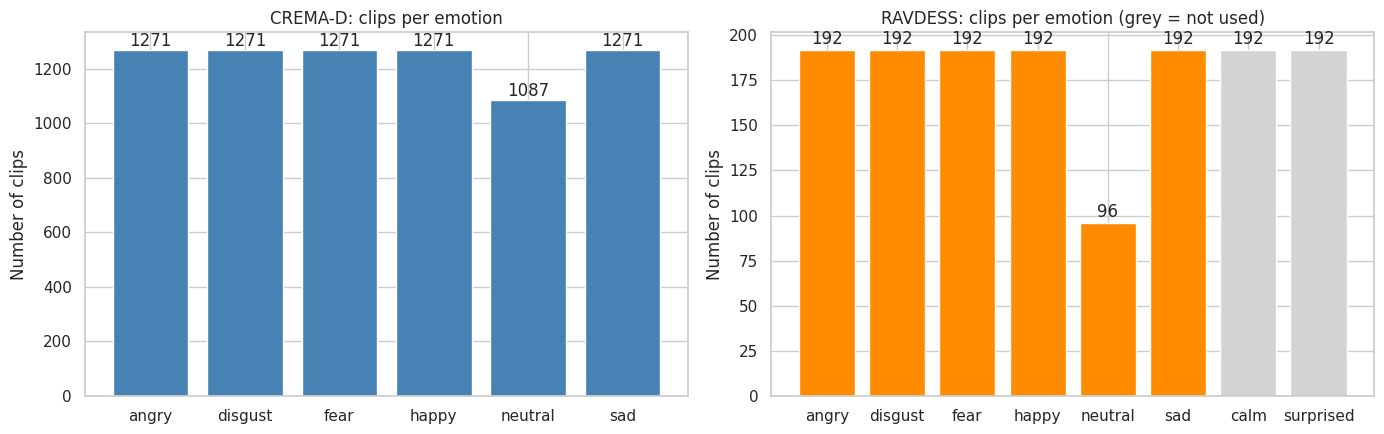

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid")

FIG_DIR = f"{PROJECT_DIR}/figures"
os.makedirs(FIG_DIR, exist_ok=True)

order6 = ["angry", "disgust", "fear", "happy", "neutral", "sad"]
order8 = order6 + ["calm", "surprised"]
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

c = meta[meta.dataset == "CREMA-D"]["emotion"].value_counts().reindex(order6)
axes[0].bar(c.index, c.values, color="steelblue")
axes[0].set_title("CREMA-D: clips per emotion")
for i, v in enumerate(c.values):
    axes[0].text(i, v + 15, str(v), ha="center")

r = meta[meta.dataset == "RAVDESS"]["emotion_original"].value_counts().reindex(order8)
axes[1].bar(r.index, r.values, color=["darkorange"] * 6 + ["lightgrey"] * 2)
axes[1].set_title("RAVDESS: clips per emotion (grey = not used)")
for i, v in enumerate(r.values):
    axes[1].text(i, v + 3, str(v), ha="center")

for ax in axes:
    ax.set_ylabel("Number of clips")
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/01_class_distribution.png", dpi=150)
plt.show()

### Speaker demographics
Plots the CREMA-D speakers by gender, age and race. These groups are used to keep the train, val and test speakers similar.

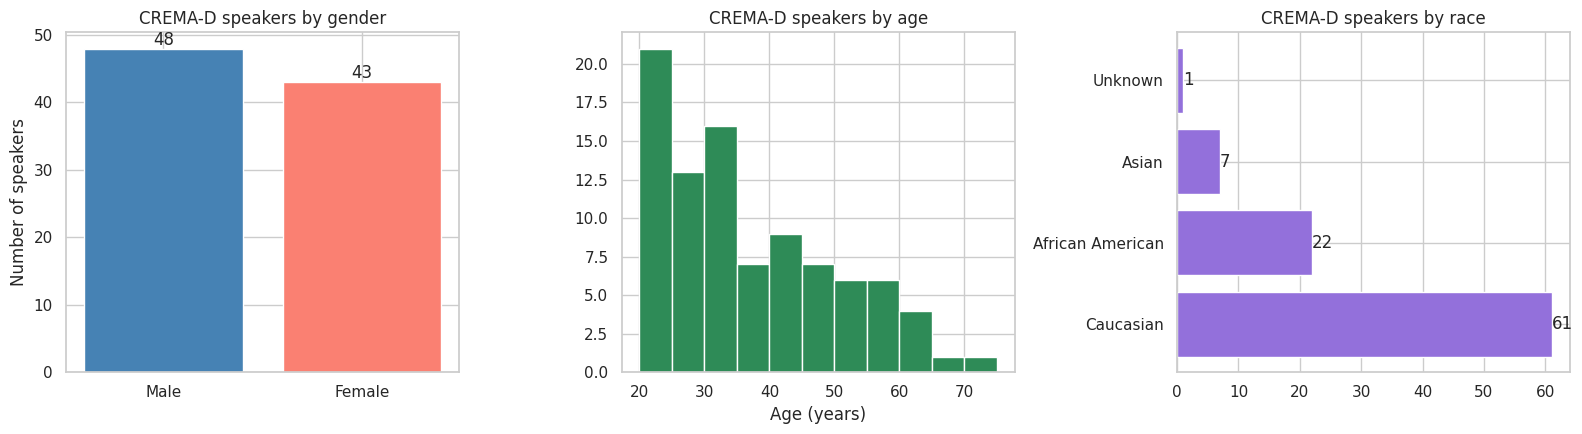

Race (% of speakers):
 race
Caucasian           67.0
African American    24.2
Asian                7.7
Unknown              1.1
Name: proportion, dtype: float64

Ethnicity (% of speakers):
 ethnicity
Not Hispanic    89.0
Hispanic        11.0
Name: proportion, dtype: float64


In [9]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

g = demo["gender"].value_counts()
axes[0].bar(g.index, g.values, color=["steelblue", "salmon"])
axes[0].bar_label(axes[0].containers[0])
axes[0].set_title("CREMA-D speakers by gender")
axes[0].set_ylabel("Number of speakers")

axes[1].hist(demo["age"], bins=range(20, 80, 5), color="seagreen", edgecolor="white")
axes[1].set_title("CREMA-D speakers by age")
axes[1].set_xlabel("Age (years)")

rc = demo["race"].value_counts()
axes[2].barh(rc.index, rc.values, color="mediumpurple")
axes[2].bar_label(axes[2].containers[0])
axes[2].set_title("CREMA-D speakers by race")

plt.tight_layout()
plt.savefig(f"{FIG_DIR}/02_speaker_demographics.png", dpi=150)
plt.show()

print("Race (% of speakers):\n", (demo["race"].value_counts(normalize=True) * 100).round(1))
print("\nEthnicity (% of speakers):\n", (demo["ethnicity"].value_counts(normalize=True) * 100).round(1))

### Emotion by gender and clip duration
Plots clips per emotion split by gender, and the clip length in both datasets. It also prints how many clips fit inside a few candidate fixed lengths.

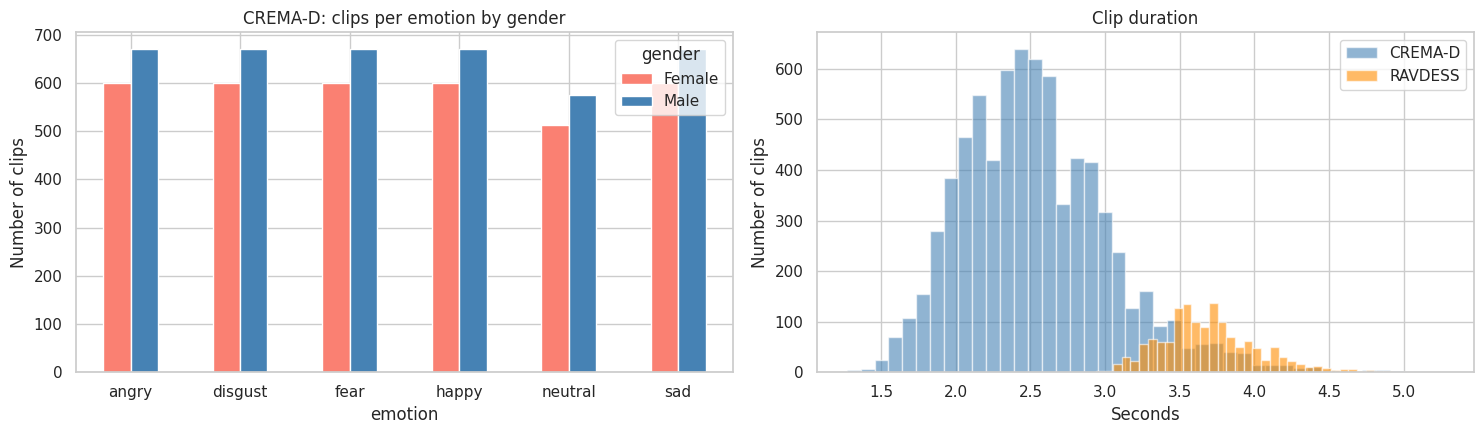

<= 2.5s: {'CREMA-D': 49.7, 'RAVDESS': 0.0}
<= 3.0s: {'CREMA-D': 83.2, 'RAVDESS': 0.1}
<= 3.5s: {'CREMA-D': 95.2, 'RAVDESS': 26.2}
<= 4.0s: {'CREMA-D': 98.9, 'RAVDESS': 82.3}


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))


cd = meta[meta.dataset == "CREMA-D"]
eg = pd.crosstab(cd["emotion"], cd["gender"]).reindex(order6)
eg.plot(kind="bar", ax=axes[0], color=["salmon", "steelblue"], rot=0)
axes[0].set_title("CREMA-D: clips per emotion by gender")
axes[0].set_ylabel("Number of clips")

for name, col in [("CREMA-D", "steelblue"), ("RAVDESS", "darkorange")]:
    d = meta.loc[(meta.dataset == name) & meta.usable, "duration_s"]
    axes[1].hist(d, bins=40, alpha=0.6, label=name, color=col)
axes[1].set_title("Clip duration")
axes[1].set_xlabel("Seconds")
axes[1].set_ylabel("Number of clips")
axes[1].legend()

plt.tight_layout()
plt.savefig(f"{FIG_DIR}/03_emotion_gender_and_duration.png", dpi=150)
plt.show()


for L in [2.5, 3.0, 3.5, 4.0]:
    pct = meta[meta.usable].groupby("dataset")["duration_s"].apply(lambda s: (s <= L).mean() * 100)
    print(f"<= {L}s:", pct.round(1).to_dict())

### Silence in the clips
Measures the silence at the start and end of every clip with a 30 dB threshold. The plots show how much of each clip is silence and how long the speech is after trimming, which decides the fixed clip length.

  0%|          | 0/8882 [00:00<?, ?it/s]

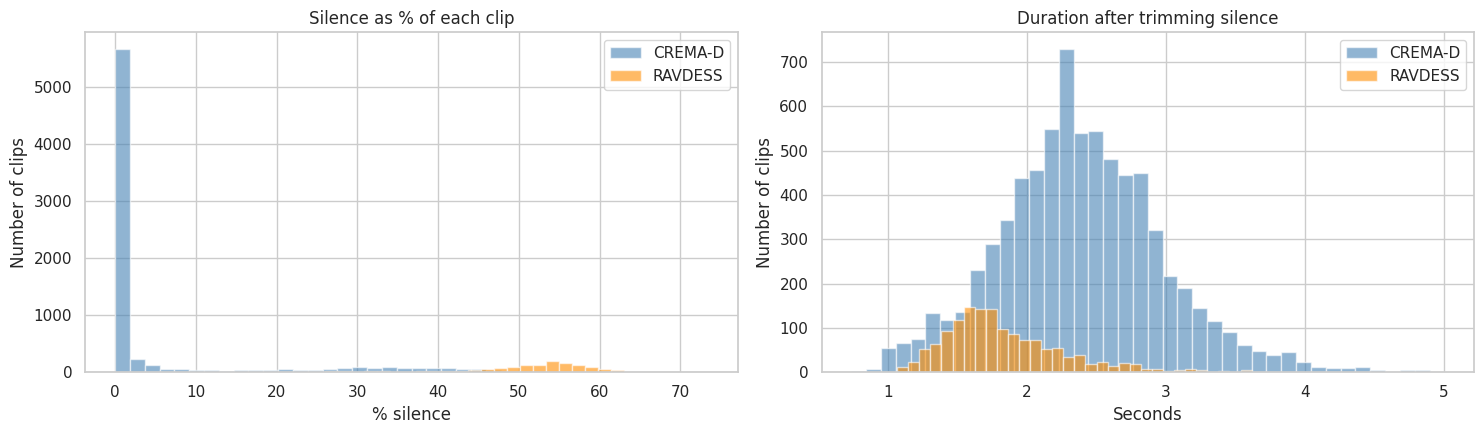

Average silence (%): {'CREMA-D': 6.0, 'RAVDESS': 50.6}
Speech <= 2.0s: {'CREMA-D': 23.6, 'RAVDESS': 71.7}
Speech <= 2.5s: {'CREMA-D': 58.8, 'RAVDESS': 91.6}
Speech <= 3.0s: {'CREMA-D': 86.1, 'RAVDESS': 98.1}
Speech <= 3.5s: {'CREMA-D': 95.9, 'RAVDESS': 99.5}


In [11]:
def silence_info(path, top_db=30):
    y, sr = sf.read(path, dtype="float32")
    if y.ndim > 1:
        y = y.mean(axis=1)
    _, (start, end) = librosa.effects.trim(y, top_db=top_db)
    return pd.Series({"lead_sil_s": start / sr,
                      "trail_sil_s": (len(y) - end) / sr,
                      "speech_s": (end - start) / sr})

sil = meta.loc[meta.usable, "path"].progress_apply(silence_info)
meta = meta.drop(columns=["lead_sil_s", "trail_sil_s", "speech_s", "silence_pct"], errors="ignore").join(sil)
meta["silence_pct"] = 100 * (1 - meta["speech_s"] / meta["duration_s"])

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
for name, col in [("CREMA-D", "steelblue"), ("RAVDESS", "darkorange")]:
    m = meta[(meta.dataset == name) & meta.usable]
    axes[0].hist(m["silence_pct"], bins=40, alpha=0.6, label=name, color=col)
    axes[1].hist(m["speech_s"], bins=40, alpha=0.6, label=name, color=col)
axes[0].set_title("Silence as % of each clip");       axes[0].set_xlabel("% silence")
axes[1].set_title("Duration after trimming silence");  axes[1].set_xlabel("Seconds")
for ax in axes:
    ax.set_ylabel("Number of clips"); ax.legend()
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/04_silence.png", dpi=150)
plt.show()

print("Average silence (%):", meta.groupby("dataset")["silence_pct"].mean().round(1).to_dict())
for L in [2.0, 2.5, 3.0, 3.5]:
    pct = meta[meta.usable].groupby("dataset")["speech_s"].apply(lambda s: (s <= L).mean() * 100)
    print(f"Speech <= {L}s:", pct.round(1).to_dict())

meta.to_csv(f"{PROJECT_DIR}/metadata.csv", index=False)

### Human listener agreement
Downloads the CREMA-D listener ratings and compares the voice-only majority vote with the intended emotion. This gives a human reference score and shows which emotions people confuse. The votes are added to metadata.csv.

Columns found: ['Unnamed: 0', 'FileName', 'VoiceVote', 'VoiceLevel', 'FaceVote', 'FaceLevel', 'MultiModalVote', 'MultiModalLevel']


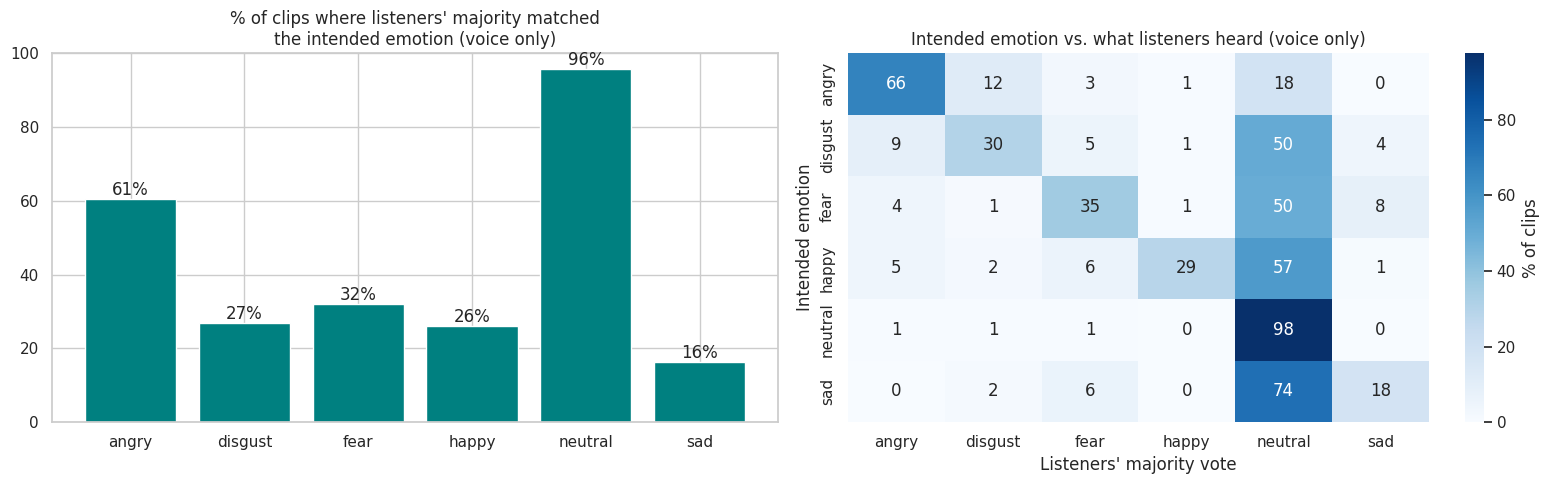

Overall agreement: 41.6 %
listener_vote
neutral    3897
angry       986
fear        645
tie         644
disgust     547
sad         370
happy       353
Name: count, dtype: int64


In [13]:
URL = ("https://raw.githubusercontent.com/CheyneyComputerScience/"
       "CREMA-D/master/processedResults/summaryTable.csv")
votes = pd.read_csv(URL)
print("Columns found:", votes.columns.tolist())

def find_col(df, name):
    for c in df.columns:
        if str(c).strip().lower() == name.lower():
            return c
    raise ValueError(f"No '{name}' column. Columns are: {df.columns.tolist()}")

fname_col, vote_col = find_col(votes, "filename"), find_col(votes, "voicevote")
votes["file_stem"] = votes[fname_col].astype(str).str.replace(r"\.\w+$", "", regex=True)
votes = votes.rename(columns={vote_col: "VoiceVote"})

LETTER = {"A": "angry", "D": "disgust", "F": "fear", "H": "happy", "N": "neutral", "S": "sad"}
cd = meta[meta.dataset == "CREMA-D"].copy()
cd["file_stem"] = cd["file"].str[:-4].str.replace(r"_X$", "_XX", regex=True)
cd = cd.merge(votes[["file_stem", "VoiceVote"]], on="file_stem", how="left")

def listener_label(v):
    if pd.isna(v): return "no rating"
    v = str(v)
    return "tie" if ":" in v else LETTER.get(v, "tie")

cd["listener_vote"] = cd["VoiceVote"].apply(listener_label)
cd["listeners_agree"] = cd["listener_vote"] == cd["emotion"]

agree = cd.groupby("emotion")["listeners_agree"].mean().reindex(order6) * 100
clear = cd[cd.listener_vote.isin(order6)]
cm = pd.crosstab(clear["emotion"], clear["listener_vote"], normalize="index").reindex(index=order6, columns=order6) * 100

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
axes[0].bar(agree.index, agree.values, color="teal")
axes[0].bar_label(axes[0].containers[0], fmt="%.0f%%")
axes[0].set_ylim(0, 100)
axes[0].set_title("% of clips where listeners' majority matched\nthe intended emotion (voice only)")
sns.heatmap(cm, annot=True, fmt=".0f", cmap="Blues", ax=axes[1], cbar_kws={"label": "% of clips"})
axes[1].set_title("Intended emotion vs. what listeners heard (voice only)")
axes[1].set_xlabel("Listeners' majority vote"); axes[1].set_ylabel("Intended emotion")
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/05_human_agreement.png", dpi=150)
plt.show()

print("Overall agreement:", round(cd["listeners_agree"].mean() * 100, 1), "%")
print(cd["listener_vote"].value_counts())


meta = meta.drop(columns=["listener_vote", "listeners_agree"], errors="ignore")
meta = meta.merge(cd[["file", "listener_vote", "listeners_agree"]], on="file", how="left")
meta.to_csv(f"{PROJECT_DIR}/metadata.csv", index=False)

### Waveforms and spectrograms of the six emotions
Shows the same speaker saying the same sentence in all six emotions, as waveform and log-Mel spectrogram, with audio players. This gives a first look at how the emotions differ.

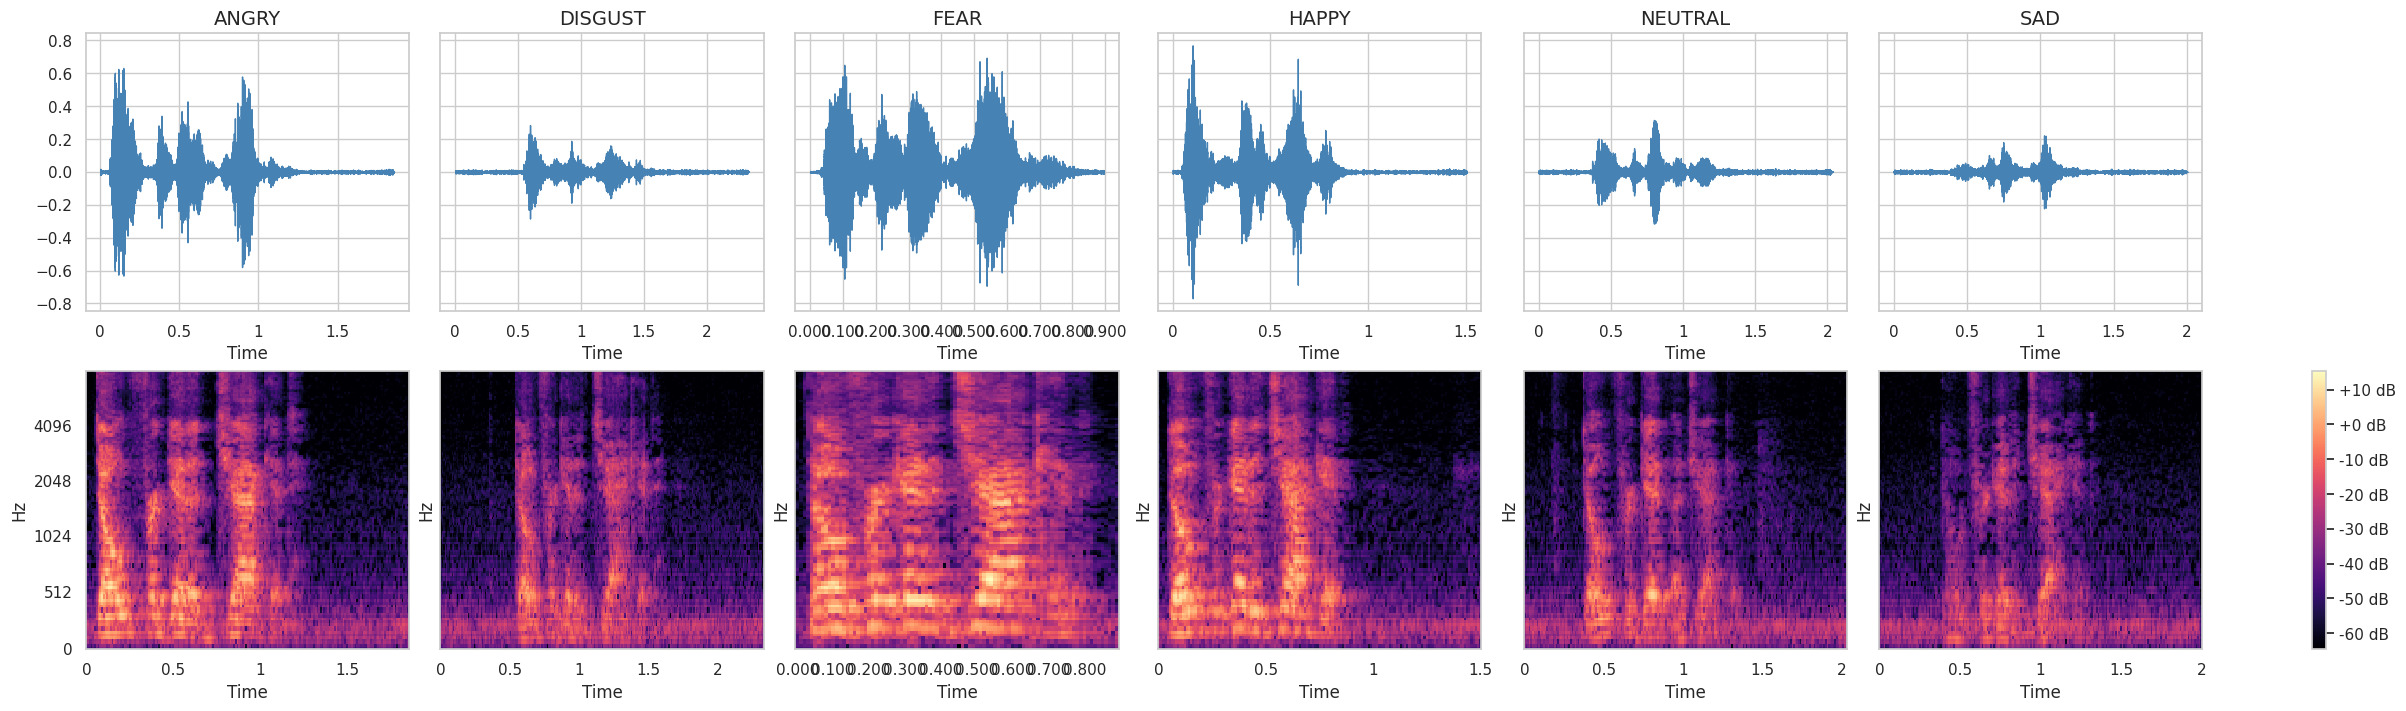

ANGRY


DISGUST


FEAR


HAPPY


NEUTRAL


SAD


In [16]:
import librosa.display
from IPython.display import Audio, display

SR = 16000
spk, sent = "crema_1001", "DFA"
ex = meta[(meta.speaker_id == spk) & (meta.sentence == sent)].set_index("emotion")


clips, specs = {}, {}
for emo in order6:
    y, _ = librosa.load(ex.loc[emo, "path"], sr=SR)
    y, _ = librosa.effects.trim(y, top_db=30)
    S = librosa.feature.melspectrogram(y=y, sr=SR, n_fft=400, hop_length=160, n_mels=128)
    clips[emo], specs[emo] = y, librosa.power_to_db(S, ref=1.0)
top = max(s.max() for s in specs.values())

fig, axes = plt.subplots(2, 6, figsize=(24, 7), sharey="row", constrained_layout=True)
for i, emo in enumerate(order6):
    librosa.display.waveshow(clips[emo], sr=SR, ax=axes[0, i], color="steelblue")
    axes[0, i].set_title(emo.upper(), fontsize=14)
    img = librosa.display.specshow(specs[emo], sr=SR, hop_length=160, x_axis="time",
                                   y_axis="mel", ax=axes[1, i], cmap="magma",
                                   vmin=top - 80, vmax=top)
fig.colorbar(img, ax=axes[1, :], format="%+2.0f dB")
plt.savefig(f"{FIG_DIR}/06_waveforms_spectrograms.png", dpi=150)
plt.show()


for emo in order6:
    print(emo.upper()); display(Audio(clips[emo], rate=SR))

### Loudness, pitch and brightness by emotion
Computes loudness, pitch and spectral centroid on a sample of up to 40 clips per dataset, emotion and gender. The box plots show which simple acoustic features change with emotion and how the two datasets differ.

Clips in sample: 960


  0%|          | 0/960 [00:00<?, ?it/s]

/tmp/ipykernel_2253/1557174293.py:16: RuntimeWarning: All-NaN slice encountered
  "pitch_hz": np.nanmedian(f0),
/usr/local/lib/python3.13/dist-packages/numpy/lib/_nanfunctions_impl.py:2053: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,


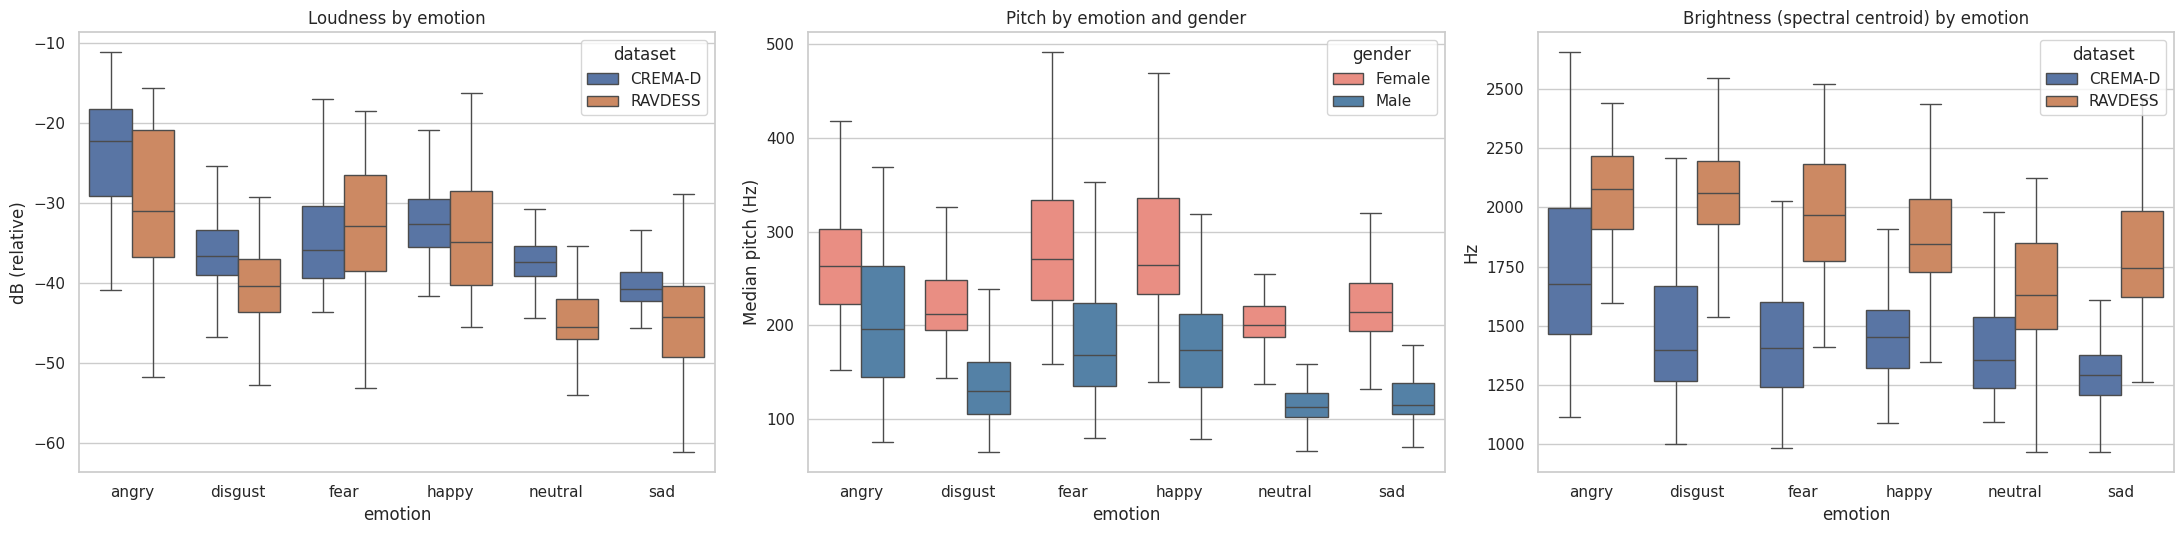

                 loudness_db  pitch_hz  brightness_hz
dataset emotion                                      
CREMA-D angry          -22.2     231.0         1676.7
        disgust        -36.6     176.6         1397.2
        fear           -35.8     199.3         1403.7
        happy          -32.6     219.9         1451.6
        neutral        -37.3     157.3         1354.4
        sad            -40.7     154.6         1289.8
RAVDESS angry          -30.9     243.3         2078.8
        disgust        -40.3     196.2         2060.9
        fear           -32.9     266.8         1965.9
        happy          -34.8     233.0         1845.1
        neutral        -45.4     171.1         1630.1
        sad            -44.2     192.5         1744.6


In [17]:

sample = (meta[meta.usable & meta.emotion.notna()]
          .sample(frac=1, random_state=42)
          .groupby(["dataset", "emotion", "gender"])
          .head(40))
print("Clips in sample:", len(sample))

def acoustic_features(path):
    y, _ = librosa.load(path, sr=SR)
    y, _ = librosa.effects.trim(y, top_db=30)
    rms = librosa.feature.rms(y=y)[0]
    f0, voiced, _ = librosa.pyin(y, fmin=65, fmax=500, sr=SR, frame_length=1024)
    f0 = f0[voiced] if voiced.any() else np.array([np.nan])
    return pd.Series({
        "loudness_db": 20 * np.log10(rms.mean() + 1e-9),
        "pitch_hz": np.nanmedian(f0),
        "pitch_var_hz": np.nanstd(f0),
        "brightness_hz": librosa.feature.spectral_centroid(y=y, sr=SR)[0].mean(),
    })

feats = sample.join(sample["path"].progress_apply(acoustic_features))

fig, axes = plt.subplots(1, 3, figsize=(22, 5.5))
sns.boxplot(data=feats, x="emotion", y="loudness_db", hue="dataset", order=order6,
            ax=axes[0], showfliers=False)
axes[0].set_title("Loudness by emotion"); axes[0].set_ylabel("dB (relative)")
sns.boxplot(data=feats, x="emotion", y="pitch_hz", hue="gender", order=order6, ax=axes[1],
            showfliers=False, palette={"Female": "salmon", "Male": "steelblue"})
axes[1].set_title("Pitch by emotion and gender"); axes[1].set_ylabel("Median pitch (Hz)")
sns.boxplot(data=feats, x="emotion", y="brightness_hz", hue="dataset", order=order6,
            ax=axes[2], showfliers=False)
axes[2].set_title("Brightness (spectral centroid) by emotion"); axes[2].set_ylabel("Hz")
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/07_loudness_pitch_brightness.png", dpi=150)
plt.show()

print(feats.groupby(["dataset", "emotion"])[["loudness_db", "pitch_hz", "brightness_hz"]].median().round(1))
feats.to_csv(f"{PROJECT_DIR}/acoustic_features_sample.csv", index=False)

### t-SNE of MFCC features
Takes all clips of 10 CREMA-D speakers, computes MFCC statistics and plots them in 2D, coloured by emotion, speaker and gender. It also checks how often the nearest clip has the same speaker or the same emotion.

Clips: 820 from 10 speakers


  0%|          | 0/820 [00:00<?, ?it/s]

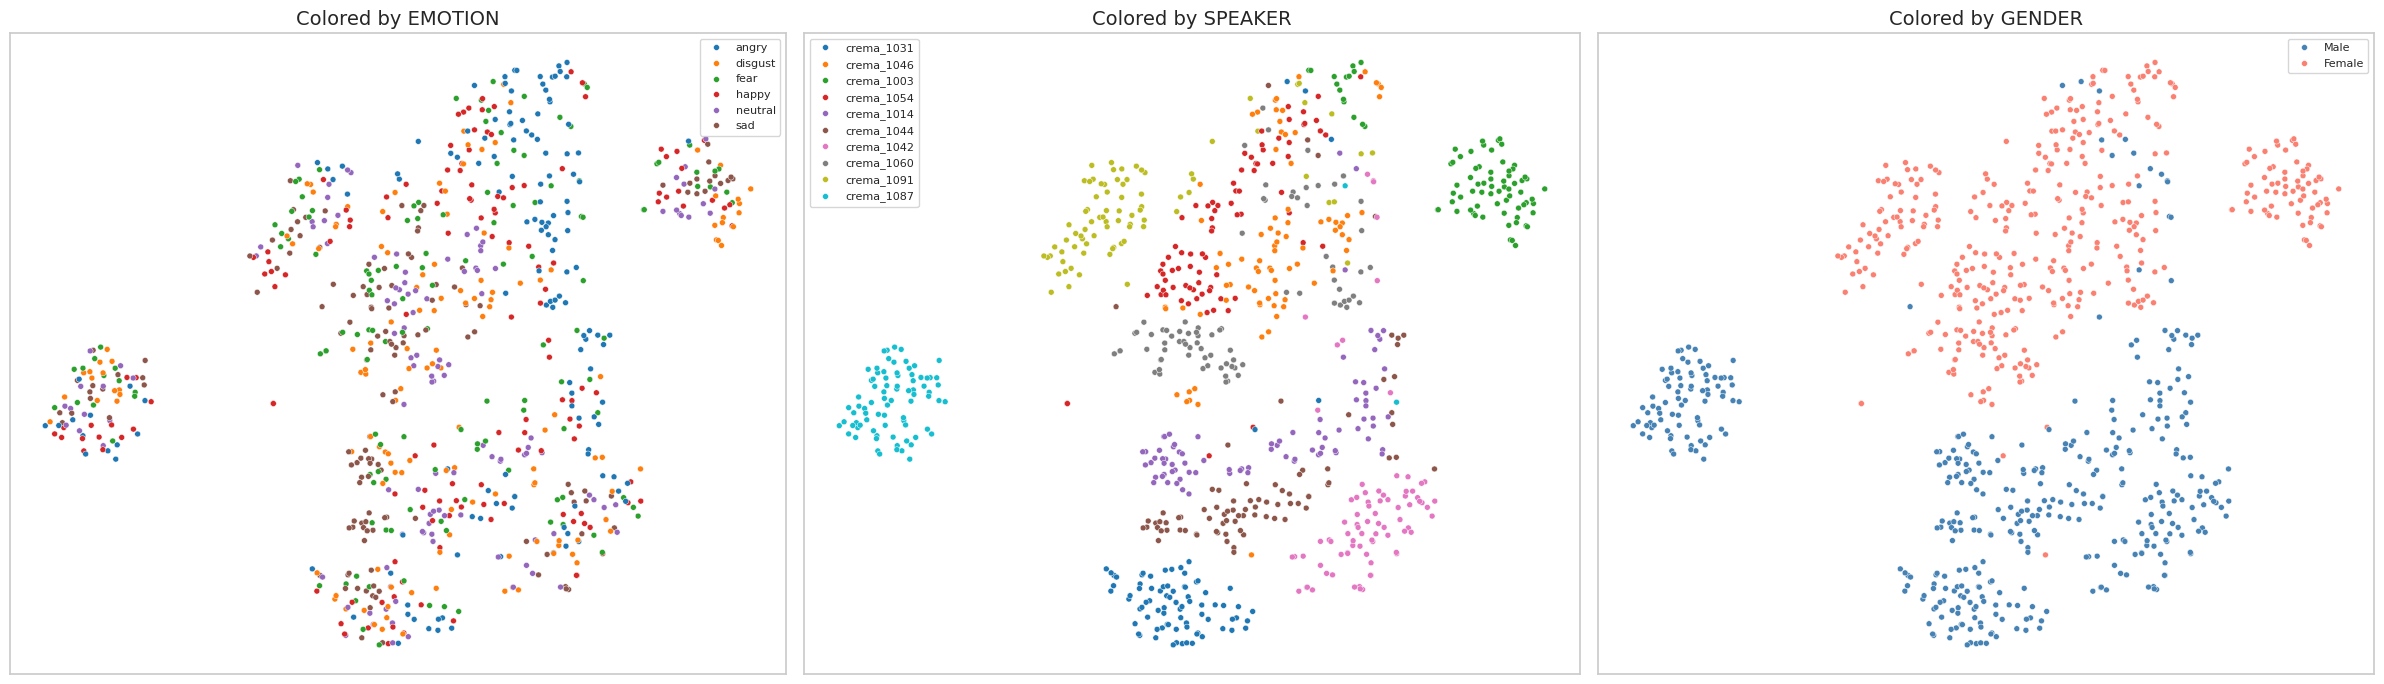

Closest clip is from the SAME SPEAKER:  90%  (chance = 10%)
Closest clip has the SAME EMOTION:     35%  (chance ≈ 17%)


In [18]:
from sklearn.manifold import TSNE
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors


spk_pick = demo.sample(frac=1, random_state=0).groupby("gender").head(5)["actor_num"]
sub = meta[(meta.dataset == "CREMA-D") & meta.usable & meta.actor_num.isin(spk_pick)].copy()
print("Clips:", len(sub), "from", sub.speaker_id.nunique(), "speakers")

def mfcc_stats(path):
    y, _ = librosa.load(path, sr=SR)
    y, _ = librosa.effects.trim(y, top_db=30)
    m = librosa.feature.mfcc(y=y, sr=SR, n_mfcc=40, n_fft=400, hop_length=160)
    return np.concatenate([m.mean(axis=1), m.std(axis=1)])

X = StandardScaler().fit_transform(np.vstack(sub["path"].progress_apply(mfcc_stats).values))
emb = TSNE(n_components=2, perplexity=30, random_state=42).fit_transform(X)
sub["tsne_x"], sub["tsne_y"] = emb[:, 0], emb[:, 1]

panels = [("emotion", "Colored by EMOTION", "tab10", order6),
          ("speaker_id", "Colored by SPEAKER", "tab10", None),
          ("gender", "Colored by GENDER", {"Female": "salmon", "Male": "steelblue"}, None)]
fig, axes = plt.subplots(1, 3, figsize=(24, 7))
for ax, (col, title, pal, order) in zip(axes, panels):
    sns.scatterplot(data=sub, x="tsne_x", y="tsne_y", hue=col, hue_order=order,
                    palette=pal, s=18, ax=ax)
    ax.set_title(title, fontsize=14)
    ax.set_xticks([]); ax.set_yticks([]); ax.set_xlabel(""); ax.set_ylabel("")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/08_tsne_emotion_speaker_gender.png", dpi=150)
plt.show()


idx = NearestNeighbors(n_neighbors=2).fit(X).kneighbors(X, return_distance=False)[:, 1]
same_spk = (sub["speaker_id"].values[idx] == sub["speaker_id"].values).mean() * 100
same_emo = (sub["emotion"].values[idx] == sub["emotion"].values).mean() * 100
print(f"Closest clip is from the SAME SPEAKER :  {same_spk:.0f}%  (chance = 10%)")
print(f"Closest clip has the SAME EMOTION :     {same_emo:.0f}%  (chance ≈ 17%)")

### Preprocessing pipeline
Picks the fixed clip length from the 95th percentile of speech duration and defines the cleaning steps: 16 kHz mono, trim silence, peak-normalise, centre crop or zero pad, then log-Mel. One RAVDESS clip is plotted before and after.

95% of CREMA-D speech is <= 3.40s -> fixed length = 3.5s
Every clip becomes a 128 x 351 log-Mel spectrogram


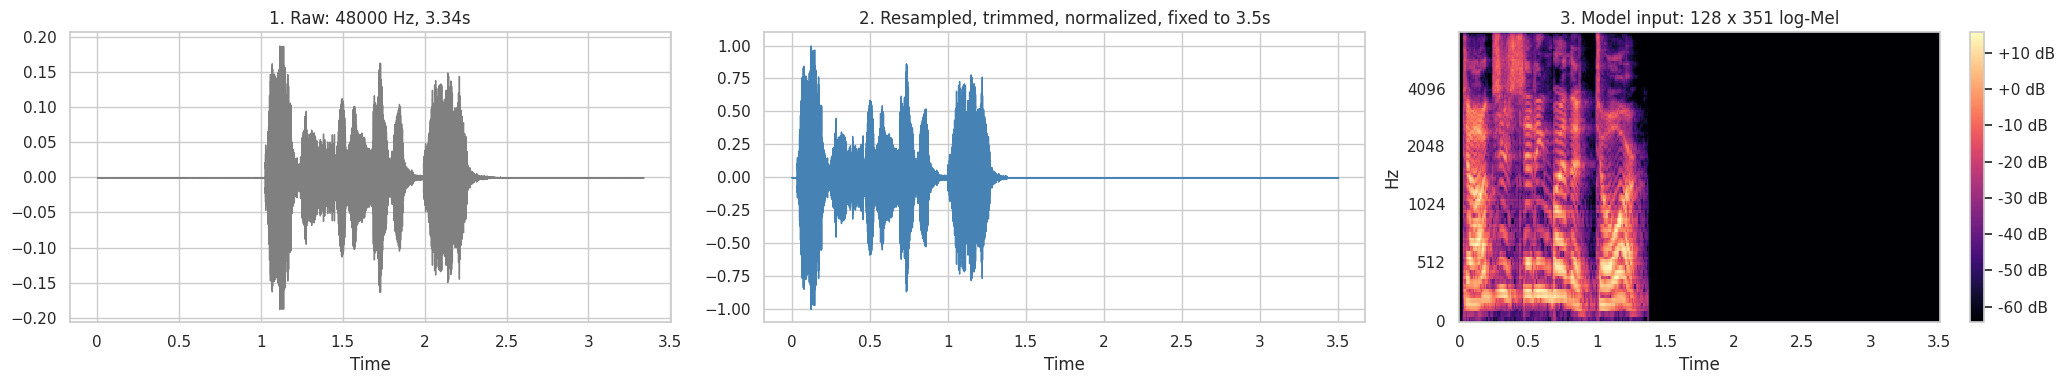

In [19]:
N_MELS, N_FFT, HOP = 128, 400, 160
speech = meta.loc[(meta.dataset == "CREMA-D") & meta.usable, "speech_s"]
CLIP_S = float(min(4.0, np.ceil(speech.quantile(0.95) * 2) / 2))
N_SAMPLES = int(CLIP_S * SR)
N_FRAMES = 1 + N_SAMPLES // HOP
print(f"95% of CREMA-D speech is <= {speech.quantile(0.95):.2f}s -> fixed length = {CLIP_S}s")
print(f"Every clip becomes a {N_MELS} x {N_FRAMES} log-Mel spectrogram")

def clean_audio(path):
    y, _ = librosa.load(path, sr=SR, mono=True)
    y, _ = librosa.effects.trim(y, top_db=30)
    y = y / (np.max(np.abs(y)) + 1e-9)
    if len(y) >= N_SAMPLES:
        s = (len(y) - N_SAMPLES) // 2
        y = y[s:s + N_SAMPLES]
    else:
        y = np.pad(y, (0, N_SAMPLES - len(y)))
    return y

def to_logmel(y):
    S = librosa.feature.melspectrogram(y=y, sr=SR, n_fft=N_FFT, hop_length=HOP, n_mels=N_MELS)
    return librosa.power_to_db(S, ref=1.0, top_db=80)


p = meta.loc[(meta.dataset == "RAVDESS") & (meta.emotion == "angry"), "path"].iloc[0]
raw, raw_sr = librosa.load(p, sr=None)
y = clean_audio(p)

fig, axes = plt.subplots(1, 3, figsize=(21, 4))
librosa.display.waveshow(raw, sr=raw_sr, ax=axes[0], color="grey")
axes[0].set_title(f"1. Raw: {raw_sr} Hz, {len(raw)/raw_sr:.2f}s")
librosa.display.waveshow(y, sr=SR, ax=axes[1], color="steelblue")
axes[1].set_title(f"2. Resampled, trimmed, normalized, fixed to {CLIP_S}s")
img = librosa.display.specshow(to_logmel(y), sr=SR, hop_length=HOP, x_axis="time",
                               y_axis="mel", ax=axes[2], cmap="magma")
axes[2].set_title(f"3. Model input: {N_MELS} x {N_FRAMES} log-Mel")
fig.colorbar(img, ax=axes[2], format="%+2.0f dB")
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/09_preprocessing_before_after.png", dpi=150)
plt.show()

### Build the spectrogram dataset
Runs the pipeline on every usable clip in the six shared emotions and stores the result as one array. Saves logmel_X.npy and logmel_index.csv.

In [20]:
data = meta[meta.usable & meta.emotion.notna()].reset_index(drop=True)
data["label"] = data["emotion"].map({e: i for i, e in enumerate(order6)})
print("Clips to process:", len(data), data.groupby("dataset").size().to_dict())

X = np.zeros((len(data), N_MELS, N_FRAMES), dtype=np.float16)
for i, p in enumerate(tqdm(data["path"], desc="Preprocessing")):
    X[i] = to_logmel(clean_audio(p))


print("\nShape:", X.shape, "| Size:", round(X.nbytes / 1e9, 2), "GB")
print("All values valid (no NaN/inf):", bool(np.isfinite(X).all()))
print("Value range (dB):", float(X.min()), "to", float(X.max()))
print("\nClips per emotion:\n", pd.crosstab(data["emotion"], data["dataset"]).reindex(order6))


np.save(f"{PROJECT_DIR}/logmel_X.npy", X)
data.to_csv(f"{PROJECT_DIR}/logmel_index.csv", index=False)
print("\nSaved logmel_X.npy and logmel_index.csv to", PROJECT_DIR)

Clips to process: 8498 {'CREMA-D': 7442, 'RAVDESS': 1056}


Preprocessing:   0%|          | 0/8498 [00:00<?, ?it/s]


Shape: (8498, 128, 351) | Size: 0.76 GB
All values valid (no NaN/inf): True
Value range (dB): -100.0 to 26.71875

Clips per emotion:
 dataset  CREMA-D  RAVDESS
emotion                  
angry       1271      192
disgust     1271      192
fear        1271      192
happy       1271      192
neutral     1087       96
sad         1271      192

Saved logmel_X.npy and logmel_index.csv to /content/drive/MyDrive/SER_Project


### Speaker-independent split and normalisation statistics
Assigns each CREMA-D speaker to train, val or test (about 15% each for val and test) within every gender and race group, so no speaker appears in two splits. All RAVDESS clips become a separate test set. The per-mel-band mean and standard deviation are computed on the training clips only.

In [21]:

if "X" not in globals() or "data" not in globals():
    X = np.load(f"{PROJECT_DIR}/logmel_X.npy")
    data = pd.read_csv(f"{PROJECT_DIR}/logmel_index.csv")


rng = np.random.default_rng(42)
spk = demo.copy()
spk["speaker_id"] = "crema_" + spk["actor_num"].astype(str)
split_of = {}
for _, g in spk.groupby(["gender", "race"]):
    ids = rng.permutation(g["speaker_id"].values)
    n_test = n_val = round(0.15 * len(ids))
    for j, s in enumerate(ids):
        split_of[s] = "test" if j < n_test else "val" if j < n_test + n_val else "train"
data["split"] = data["speaker_id"].map(split_of).fillna("ravdess_test")

print("Every speaker in exactly one split:", data.groupby("speaker_id")["split"].nunique().max() == 1)
spk_tab = data.drop_duplicates("speaker_id")
print("\n--- Speakers per split, by gender ---\n", pd.crosstab(spk_tab["split"], spk_tab["gender"], margins=True))
print("\n--- CREMA-D speakers per split, by race ---\n", pd.crosstab(spk_tab["split"], spk_tab["race"]))
print("\n--- Clips per split, by emotion ---\n", pd.crosstab(data["split"], data["emotion"], margins=True).reindex(columns=order6 + ["All"]))


tr = np.where(data["split"] == "train")[0]
Xtr = X[tr].astype(np.float32)
np.savez(f"{PROJECT_DIR}/norm_stats.npz", mean=Xtr.mean(axis=(0, 2)), std=Xtr.std(axis=(0, 2)) + 1e-6)
del Xtr

data.to_csv(f"{PROJECT_DIR}/logmel_index.csv", index=False)
print("\nSaved split to logmel_index.csv and norm_stats.npz to", PROJECT_DIR)

Every speaker in exactly one split: True

--- Speakers per split, by gender ---
 gender        Female  Male  All
split                          
ravdess_test      12    12   24
test               6     7   13
train             31    34   65
val                6     7   13
All               55    60  115

--- CREMA-D speakers per split, by race ---
 race   African American  Asian  Caucasian  Unknown
split                                             
test                  3      1          9        0
train                16      5         43        1
val                   3      1          9        0

--- Clips per split, by emotion ---
 emotion       angry  disgust  fear  happy  neutral   sad   All
split                                                         
ravdess_test    192      192   192    192       96   192  1056
test            179      179   179    179      153   179  1048
train           910      910   910    910      779   910  5329
val             182      182   182    182

## No-volume-scaling variant
Same cleaning as above but without per-clip peak normalisation, and with a fixed dB floor (top_db=None), so real loudness is kept. Used by the CNN (noscale run), BiLSTM, Transformer and WavLM. Output when run: `Files found: 8498 of 8498`, `Saved: (8498, 128, 351) | range: -100.0 to 26.71875 dB`. Cell outputs were not saved with this notebook; the generated files are logmel_X_noscale.npy and norm_stats_noscale.npz.

In [ ]:
import glob, os, numpy as np, pandas as pd, librosa, kagglehub
from tqdm.auto import tqdm

SR, N_MELS, N_FFT, HOP = 16000, 128, 400, 160
CLIP_S = 3.5
N_SAMPLES = int(CLIP_S * SR)
N_FRAMES = 1 + N_SAMPLES // HOP

crema_root = kagglehub.dataset_download("ejlok1/cremad")
ravdess_root = kagglehub.dataset_download("uwrfkaggler/ravdess-emotional-speech-audio")
all_wavs = (glob.glob(os.path.join(crema_root, "**", "*.wav"), recursive=True) +
            glob.glob(os.path.join(ravdess_root, "**", "*.wav"), recursive=True))
path_of = {os.path.basename(p): p for p in all_wavs}

data = pd.read_csv(f"{PROJECT_DIR}/logmel_index.csv")
data["path"] = data["file"].map(path_of)
print("Files found:", data["path"].notna().sum(), "of", len(data))

def clean_audio_noscale(path):
    y, _ = librosa.load(path, sr=SR, mono=True)
    y, _ = librosa.effects.trim(y, top_db=30)
    if len(y) >= N_SAMPLES:
        s = (len(y) - N_SAMPLES) // 2
        y = y[s:s + N_SAMPLES]
    else:
        y = np.pad(y, (0, N_SAMPLES - len(y)))
    return y

def to_logmel_fixed(y):
    S = librosa.feature.melspectrogram(y=y, sr=SR, n_fft=N_FFT, hop_length=HOP, n_mels=N_MELS)
    return librosa.power_to_db(S, ref=1.0, top_db=None)

X2 = np.zeros((len(data), N_MELS, N_FRAMES), dtype=np.float16)
for i, p in enumerate(tqdm(data["path"], desc="Spectrograms (no scaling)")):
    X2[i] = to_logmel_fixed(clean_audio_noscale(p))

tr = np.where(data["split"] == "train")[0]
Xtr = X2[tr].astype(np.float32)
np.savez(f"{PROJECT_DIR}/norm_stats_noscale.npz",
         mean=Xtr.mean(axis=(0, 2)), std=Xtr.std(axis=(0, 2)) + 1e-6)
del Xtr
np.save(f"{PROJECT_DIR}/logmel_X_noscale.npy", X2)
print("Saved:", X2.shape, "| range:", float(X2.min()), "to", float(X2.max()), "dB")